<a href="https://colab.research.google.com/github/elifkocs/Learning-Process-Ann/blob/main/learning_process_ann.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, accuracy_score, roc_auc_score

# Data Preprocessing

In [2]:
def preprocess_data(filepath):
    data = pd.read_csv(filepath)
    scaler = StandardScaler()
    X = scaler.fit_transform(data.drop('Outcome', axis=1))
    y = data['Outcome'].values
    return X, y

# Activation Functions

In [3]:
# Sigmoid
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Relu
def relu(z):
    return np.maximum(0, z)

# Forward Propagation

In [4]:
#matris formunda birinci katmandaki ağırlık ve bias değerlerini,
#ikinci katmandaki ağırlık ve bias değerlerini ve inputu da kullanarak birinci katman için net girdiyi,
#birinci katman için aktivasyon değerini, ikinci katman için net girdiyi ve ikinci katman için aktivasyon
#değerlerini hesaplamamız gerekiyor.
def forward_propagation(X, parameters):
    W1, b1, W2, b2 = parameters #katmanlara ilişkin ağırlıklar ve bias değerleri

    Z1 = np.dot(W1, X.T) + b1 #ağırlıklarla girdileri çarpıp üzerine bias değerini ekliyoruz;1.katmana ilişkin net girdi
    A1 = relu(Z1) #gizli katmanlarda relu aktivasyon fonksiyonunu kullanırız;1.katmana ilişkin aktivasyon değeri

    Z2 = np.dot(W2, A1) + b2 #ağırlık değerleriyle birinci katmandan gelen aktivasyon değerlerini çarparız ve ikinci katmana ilişkin bias değeri üzerine eklenir
    #2.katmana ilişkin net girdi oluşmuş olur
    A2 = sigmoid(Z2) #Oluşan net girdiyi sigmoid aktivasyon fonksiyonundan geçiriyoruz

    #ileri yayılımda, bu aktivasyon değerini(A2) dışarıya çıkarıp bir sonraki iterasyon için loss hesaplaması
    #yapılmak üzere dışarıya çıkarmamız gerekmektedir. Geri yayılımda kısmi türev hesaplamaları yapacağımız için
    #buradaki katmanlara ilişkin net girdi ve aktivasyon değerlerini bir tuple formunda tutuyoruz.
    cache = (Z1, A1, Z2, A2)
    return A2, cache

    #ileri yayılımda hesaplamış olduğumuz katmanlara ilişkin net girdi ve aktivasyon değerlerini cache ile saklamış olduk

# Back Propagation

In [5]:
def backward_propagation(X, Y, cache, parameters): #backpropagation dan beklediğimiz şey kısmi türevleri hesaplamasıydı
    Z1, A1, Z2, A2 = cache #tuple formunda olan cache burada çözülür ve kullanılabilir hale gelir
    W1, b1, W2, b2 = parameters #parametreleri training sürecinde gönderiyor olacağız, bunlar başlangıçtaki ağırlık değerlerimiz olacak
    #1. katmana ilişkin ağırlıklar ve ikinci katmana ilşkin ağırlıklar matris formunda tutuyoruz
    m = X.shape[0] #boyut bilgisi

    #2.katmana ilişkin gradyan hesaplamalarını ifade ediyor
    dA2 = A2 - Y #2.katmandaki ağırlıkların kısmi türevi için ihtiyaç duyduğumuz gerçek değer ile tahmin edilen değerin farkı
    dW2 = np.dot(dA2, A1.T) / m #ağırlıkların gradyanları
    db2 = np.sum(dA2, axis=1, keepdims=True) / m #bias değerlerinin gradyanları;keepdims=True boyutları koru ifadesidir;önceden gelen matrisin boyut bilgisini koru

    #1.katmana ilişkin gradyan hesaplamalarını ifade ediyor
    dZ1 = np.dot(W2.T, dA2) * relu(Z1 > 0)
    dW1 = np.dot(dZ1, X) / m #ağırlıkların gradyanları
    db1 = np.sum(dZ1, axis=1, keepdims=True) / m #bias değerlerinin gradyanları

    gradients = (dW1, db1, dW2, db2) #oluşturduğumuz gradyanları korumak için tuple yapısı kullanmayı seçtik

    return gradients

# Update Parameters

In [6]:
def update_parameters(parameters, gradients, learning_rate):

    W1, b1, W2, b2 = parameters #train sürecinde tanımlayacak olduğumuz ağırlık ve bias değerlerinin başlangıç değerleri
    dW1, db1, dW2, db2 = gradients #update parameters fonksiyonundan önce back propagation fonksiyonunu çağıracağız ve
    #back propagation fonksiyonunun çıktısını buraya göndereceğiz

    W1 -= learning_rate * dW1 #ağırlıkların eski değerlerine ekleme ya da çıkarma yaparak gradyanları learning rate ler ile çarparak güncelleyecek
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    return (W1, b1, W2, b2)

# Train and Evaluate

In [7]:
def train_and_evaluate(X_train, y_train, X_val, y_val, layer_dims, learning_rate, num_iterations):
    np.random.seed(3) #oluşturulacak olan rastgele sayılar kodu her çalıştırdığımızda aynı olsun diye

    W1 = np.random.randn(layer_dims[1], layer_dims[0]) * 0.01 #1.katmanın ağırlığını oluşturduk; numpy ın random modülünün içerisinden
    #random number ile ortalaması 0 ve standart sapması 1 olan dağılımdan rastgele sayılar üreteceğiz.Ağırlık matrisi oluşuyor olacak.
    #0.01 ile çarpıyoruz ki ağırlıkların başlangıç değerlerinin küçük olduğuna emin olalım
    b1 = np.zeros((layer_dims[1], 1)) #1.katmanın bias değerini oluşturduk;verecek olduğumuz boyut bilgisi kadar rastgele 0 lardan oluşan
    #ağırlıklar üretiyoruz

    W2 = np.random.randn(layer_dims[2], layer_dims[1]) * 0.01
    b2 = np.zeros((layer_dims[2], 1))

    parameters = (W1, b1, W2, b2) #oluşturduğumuz ağırlık ve bias değerlerini parametreler tuple ında saklıyoruz

    train_loss_list = [] #train süreci olacak ve iterasyonlar devam ettikçe train loss unu ve validasyon loss unu görmek isteyeceğimiz için
    val_loss_list = []

    for i in range(num_iterations): #iterasyonlar başlar

        # Forward Propagation #ileri yayılım başlar
        A2_train, cache_train = forward_propagation(X_train, parameters) #bağımsız değişken değerlerini ve parametreleri alır
        #A2_train;y olasılık değeridir

        # train loss
        train_loss = log_loss(y_train, A2_train.flatten()) #log loss fonksiyonu ile loss hesaplanır
        train_loss_list.append(train_loss) #boş listeye train loss u ekledik

        # val loss
        A2_val, _ = forward_propagation(X_val, parameters)
        val_loss = log_loss(y_val, A2_val.flatten()) #elimizde gerçek değerler ve tahmin edilen değerler var öyleyse loss u hesaplıyoruz
        val_loss_list.append(val_loss)

        # 1-0
        predictions_train = (A2_train > 0.5).astype(int)#accuracy ve auc hesaplamak istiyoruz bu yüzden değerleri 0.5ten büyükse 1 değilse 0 olacak şekilde dönüştürüyoruz
        predictions_val = (A2_val > 0.5).astype(int)

        # Performance metrics
        train_accuracy = accuracy_score(y_train, predictions_train.flatten()) #gerçek değerleri ve tahmin edilen değerleri alır accuracy oluşturur

        val_accuracy = accuracy_score(y_val, predictions_val.flatten())

        train_auc = roc_auc_score(y_train, A2_train.flatten())
        val_auc = roc_auc_score(y_val, A2_val.flatten())
        #Buraya kadar yapılan işlemler ileri yayılım işlemleriydi

        # Back Propagation
        gradients = backward_propagation(X_train, y_train, cache_train, parameters)#cache train;ileri yayılım bölümünde katmanlara ilişkin net
        #girdi ve aktivasyon değerlerini ifade eder, çünkü geriye yayılımda ihtiyaç duyulan yerlerde kullanılacak.parameters; train sürecindeki çalışmayı
        #başlatıyorkenki tanımlanmış olunan parametrelerdir.

        # Update Weights
        parameters = update_parameters(parameters, gradients, learning_rate) #döngünün içinde kaldığımız süre boyunca parametreler sürekli güncelleniyor olacak

        if i % 100 == 0: #yüz iterasyonda bir
            print(f"Iteration {i}: Train Loss {train_loss:.4f}, Val Loss {val_loss:.4f}, "#train ve validasyon loss unu raporla
                  f"Train Acc {train_accuracy:.4f}, Val Acc {val_accuracy:.4f}, " #train ve validasyonun accuracy skorlarını raporla
                  f"Train AUC {train_auc:.4f}, Val AUC {val_auc:.4f}") #train ve validasyonun auc değerlerini raporla

    plt.figure(figsize=(10, 5))
    plt.plot(train_loss_list, label='Training Loss')
    plt.plot(val_loss_list, label='Validation Loss')
    plt.title('Training and Validation Loss Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Log Loss')
    plt.legend()
    plt.show()
    #elimizde train ve validasyon loss larının bir listesi olacağı için bunları epoch-iterasyonlara göre nasıl değişmiş olabileceğini gözlemleyebiliriz
    return parameters

# Learning Processes

In [8]:
def main(num_iterations = 1000, learning_rate = 0.01):

    X, y = preprocess_data('/content/diabetes.csv')

    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

    layer_dims = [X_train.shape[1], 2, 1] #X_train.shape[1] diyerek değişken sayısı(kaç tane input umuz var) bilgisini aldık.0.indeks gözlem sayısını verir.
    #[X_train.shape[1], 2, 1] buradaki 2 sayısı gizli nöron sayısını ifade etmektedir, 1 ise çıktı katmanındaki nöronu ifade eder.

    parameters = train_and_evaluate(X_train, y_train, X_val, y_val, layer_dims, learning_rate, num_iterations)

    return parameters

Iteration 0: Train Loss 0.6931, Val Loss 0.6931, Train Acc 0.6531, Val Acc 0.6429, Train AUC 0.4054, Val AUC 0.3319
Iteration 100: Train Loss 0.6747, Val Loss 0.6761, Train Acc 0.6531, Val Acc 0.6429, Train AUC 0.4511, Val AUC 0.3759
Iteration 200: Train Loss 0.6634, Val Loss 0.6659, Train Acc 0.6531, Val Acc 0.6429, Train AUC 0.5051, Val AUC 0.4264
Iteration 300: Train Loss 0.6566, Val Loss 0.6599, Train Acc 0.6531, Val Acc 0.6429, Train AUC 0.5679, Val AUC 0.5009
Iteration 400: Train Loss 0.6524, Val Loss 0.6564, Train Acc 0.6531, Val Acc 0.6429, Train AUC 0.6400, Val AUC 0.5678
Iteration 500: Train Loss 0.6497, Val Loss 0.6543, Train Acc 0.6531, Val Acc 0.6429, Train AUC 0.6966, Val AUC 0.6213
Iteration 600: Train Loss 0.6481, Val Loss 0.6530, Train Acc 0.6531, Val Acc 0.6429, Train AUC 0.7360, Val AUC 0.6683
Iteration 700: Train Loss 0.6470, Val Loss 0.6523, Train Acc 0.6531, Val Acc 0.6429, Train AUC 0.7616, Val AUC 0.6968
Iteration 800: Train Loss 0.6463, Val Loss 0.6519, Train A

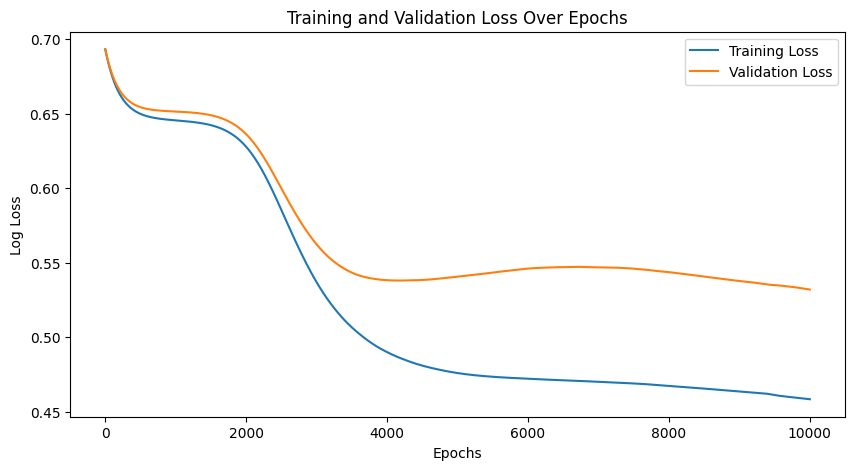

In [9]:
parameters = main(num_iterations=10000)
#grafiği yorumlarsak; model train setinde iyi öğreniyor olsa da model train setinin ezberlemeye başladı